# 04 — Multivariate Forecasting
Test whether lagged market and macroeconomic predictors improve forecasts over target-price lags alone. Compare feature sets with and without the Japan import-price index.

In [16]:
from pathlib import Path
import sys, warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Resolve project root from any nested notebook directory.
HERE = Path.cwd().resolve()
REPO_ROOT = next((p for p in [HERE, *HERE.parents] if (p / "src" / "features.py").exists()), None)
if REPO_ROOT is None:
    raise FileNotFoundError("Open this notebook somewhere inside the project folder containing src/features.py.")
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))
from src.features import create_lagged_features

DATA_FILE = REPO_ROOT / "Data" / "lithium_consolidated_monthly.csv"
RESULTS_DIR = REPO_ROOT / "Results"
FIGURES_DIR = RESULTS_DIR / "figures"
TABLES_DIR = RESULTS_DIR / "tables"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
TABLES_DIR.mkdir(parents=True, exist_ok=True)

TARGET = "Selected lithium carbonate price (CNY/t)"
JAPAN_INDEX = "Japan, Import Prices, Yen Basis, Lithium Carbonates, Index, 2020 = 100"
RANDOM_STATE = 42
df = pd.read_csv(DATA_FILE)
df["Month"] = pd.to_datetime(df["Month"])
df = df.sort_values("Month").drop_duplicates("Month").set_index("Month").asfreq("MS")
df[TARGET] = pd.to_numeric(df[TARGET], errors="coerce")
print("Project root:", REPO_ROOT)
print("Data:", DATA_FILE)

from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import TimeSeriesSplit, learning_curve

EXCLUDED = {
    TARGET, "Selected target source", "Lithium carbonate price (CNY/metric tonne)",
    "China spot lithium carbonate price (CNY/t) - CSV",
    "OLD - faulty cobalt settlement series (constant; excluded)",
    "China spot price open (CNY/t) - CSV", "China spot price high (CNY/t) - CSV",
    "China spot price low (CNY/t) - CSV", "China spot price volume (CSV)",
    "China spot price change (%) - CSV",
}
ALL_PREDICTORS = [c for c in df.select_dtypes(include=np.number).columns if c not in EXCLUDED]

def supervised_frame(horizon=1, n_lags=12, exog_cols=None):
    # Each row at origin t uses only observations through t-1.
    cols = [TARGET] + (list(exog_cols) if exog_cols else [])
    raw = df[cols].copy()
    lagged = create_lagged_features(raw, columns=cols, min_lag=1, max_lag=n_lags)
    y = df[TARGET].shift(-(horizon - 1)).rename("target")
    joined = lagged.join(y)
    # Retain valid labels even when one or more optional predictors are missing.
    joined = joined.dropna(subset=["target"])
    # Re-label rows by the month being forecast, not the feature-origin month.
    target_index = joined.index + pd.offsets.MonthBegin(horizon - 1)
    joined.index = target_index
    return joined.drop(columns="target"), joined["target"]

def chronological_split(X, y, test_fraction=0.20):
    cut = int(len(X) * (1-test_fraction))
    return X.iloc[:cut], X.iloc[cut:], y.iloc[:cut], y.iloc[cut:]

def model_bank():
    return {
        "Linear Regression": make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LinearRegression()),
        "Ridge": make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), Ridge(alpha=10)),
        "KNN": make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), KNeighborsRegressor(n_neighbors=5)),
        "SVR": make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), SVR(C=10, epsilon=0.1)),
        "Random Forest": make_pipeline(SimpleImputer(strategy="median"), RandomForestRegressor(n_estimators=250, min_samples_leaf=2, random_state=RANDOM_STATE)),
        "Gradient Boosting": make_pipeline(SimpleImputer(strategy="median"), GradientBoostingRegressor(random_state=RANDOM_STATE)),
    }

def score(y, pred):
    return {"MAE": mean_absolute_error(y, pred),
            "RMSE": mean_squared_error(y, pred)**0.5,
            "R2": r2_score(y, pred)}

def calibration_residuals(X_train, y_train, model_name, calibration_fraction=0.20):
    """Out-of-sample residuals from a trailing calibration segment within training data."""
    cut = int(len(X_train) * (1-calibration_fraction))
    X_fit, X_cal = X_train.iloc[:cut], X_train.iloc[cut:]
    y_fit, y_cal = y_train.iloc[:cut], y_train.iloc[cut:]
    if len(X_fit) < 20 or len(X_cal) < 5:
        raise ValueError("Not enough training observations for residual calibration.")
    cal_model = model_bank()[model_name]
    cal_model.fit(X_fit, y_fit)
    return (y_cal - cal_model.predict(X_cal)).to_numpy()

def moving_block_sample(values, n, block=3, rng=None):
    rng = np.random.default_rng(RANDOM_STATE) if rng is None else rng
    values = np.asarray(values)
    if len(values) == 0:
        raise ValueError("Residual calibration set is empty.")
    out = []
    while len(out) < n:
        start = int(rng.integers(0, max(1, len(values)-block+1)))
        out.extend(values[start:start+block])
    return np.asarray(out[:n])

def prediction_interval(pred, residuals, n_boot=1500, block=3, seed=42):
    rng = np.random.default_rng(seed)
    sims = np.vstack([pred + moving_block_sample(residuals, len(pred), block, rng) for _ in range(n_boot)])
    return np.quantile(sims, 0.025, axis=0), np.quantile(sims, 0.975, axis=0)

def plot_forecast(y_test, pred, lower, upper, title, filename, zoom_n=36):
    fig, ax = plt.subplots(figsize=(13,5))
    ax.plot(y_test.index, y_test.values, label="Observed", linewidth=2)
    ax.plot(y_test.index, pred, label="Central prediction", linewidth=1.7)
    ax.plot(y_test.index, upper, color="tab:red", linewidth=1, label="Upper prediction")
    ax.plot(y_test.index, lower, color="tab:red", linewidth=1, label="Lower prediction")
    ax.fill_between(y_test.index, lower, upper, color="tab:red", alpha=.13, label="95% prediction interval")
    ax.set(title=title, xlabel="Target month", ylabel="Lithium carbonate price (CNY/tonne)")
    ax.grid(alpha=.25); ax.legend(); plt.tight_layout()
    fig.savefig(FIGURES_DIR / filename, dpi=180); plt.show()
    if len(y_test) > zoom_n:
        fig, ax = plt.subplots(figsize=(13,5))
        ax.plot(y_test.index[-zoom_n:], y_test.values[-zoom_n:], label="Observed", linewidth=2)
        ax.plot(y_test.index[-zoom_n:], pred[-zoom_n:], label="Central prediction")
        ax.fill_between(y_test.index[-zoom_n:], lower[-zoom_n:], upper[-zoom_n:], color="tab:red", alpha=.16, label="95% prediction interval")
        ax.set(title=title + " — zoomed view", xlabel="Target month", ylabel="CNY/tonne")
        ax.grid(alpha=.25); ax.legend(); plt.tight_layout()
        fig.savefig(FIGURES_DIR / filename.replace(".png", "_zoomed.png"), dpi=180); plt.show()

def plot_learning_curve(model, X, y, title, filename):
    cv = TimeSeriesSplit(n_splits=4)
    sizes = np.linspace(.45, 1.0, 4)
    train_sizes, train_scores, val_scores = learning_curve(
        model, X, y, cv=cv, train_sizes=sizes,
        scoring="neg_mean_squared_error", n_jobs=None
    )
    train_rmse = np.sqrt(-train_scores).mean(axis=1)
    val_rmse = np.sqrt(-val_scores).mean(axis=1)
    fig, ax = plt.subplots(figsize=(8,5))
    ax.plot(train_sizes, train_rmse, marker="o", label="Training RMSE")
    ax.plot(train_sizes, val_rmse, marker="o", label="Validation RMSE")
    ax.set(title=title, xlabel="Number of training observations", ylabel="RMSE")
    ax.grid(alpha=.25); ax.legend(); plt.tight_layout()
    fig.savefig(FIGURES_DIR / filename, dpi=180); plt.show()
    return pd.DataFrame({"Training observations":train_sizes,"Training RMSE":train_rmse,"Validation RMSE":val_rmse})

Project root: /home/schmidlucy/Lucy-Schmid.github.io
Data: /home/schmidlucy/Lucy-Schmid.github.io/Data/lithium_consolidated_monthly.csv


## Define predictor sets

In [17]:
coverage=df[ALL_PREDICTORS].notna().sum()
base_predictors=[c for c in ALL_PREDICTORS if coverage[c]>=60 and c!=JAPAN_INDEX]
with_japan=base_predictors+([JAPAN_INDEX] if JAPAN_INDEX in ALL_PREDICTORS else [])
print("Base predictor count:",len(base_predictors))
print("Japan index included:",JAPAN_INDEX in with_japan)

Base predictor count: 21
Japan index included: True


## Fit multivariate models

In [18]:
HORIZONS=[1,3,6,12]
feature_sets={"Without Japan index":base_predictors,"With Japan index":with_japan}
rows=[]; store={}
for set_name,cols in feature_sets.items():
    for h in HORIZONS:
        X,y=supervised_frame(horizon=h,n_lags=6,exog_cols=cols)
        Xtr,Xte,ytr,yte=chronological_split(X,y)
        for name,model in model_bank().items():
            model.fit(Xtr,ytr); pred=model.predict(Xte)
            rows.append({"Feature set":set_name,"Horizon":h,"Model":name,**score(yte,pred)})
            store[(set_name,h,name)]=(Xtr,Xte,ytr,yte,pred)
results=pd.DataFrame(rows).sort_values(["Horizon","RMSE"])
display(results); results.to_csv(TABLES_DIR/"multivariate_model_comparison.csv",index=False)

,Feature set,Horizon,Model,MAE,RMSE,R2
29,With Japan index,1,Gradient Boosting,5.929519e+04,6.672999e+04,-3.424843e-01
5,Without Japan index,1,Gradient Boosting,6.777515e+04,7.494808e+04,-6.935113e-01
0,Without Japan index,1,Linear Regression,6.651389e+04,8.252534e+04,-1.053249e+00
24,With Japan index,1,Linear Regression,6.388570e+04,8.297731e+04,-1.075801e+00
3,Without Japan index,1,SVR,7.554127e+04,9.499053e+04,-1.720368e+00
27,With Japan index,1,SVR,7.554167e+04,9.499088e+04,-1.720388e+00
4,Without Japan index,1,Random Forest,1.056372e+05,1.102465e+05,-2.664346e+00
28,With Japan index,1,Random Forest,1.061170e+05,1.104218e+05,-2.676013e+00
25,With Japan index,1,Ridge,9.725608e+04,1.108703e+05,-2.705930e+00
1,Without Japan index,1,Ridge,1.009756e+05,1.134634e+05,-2.881310e+00


## RMSE comparison by feature set and horizon

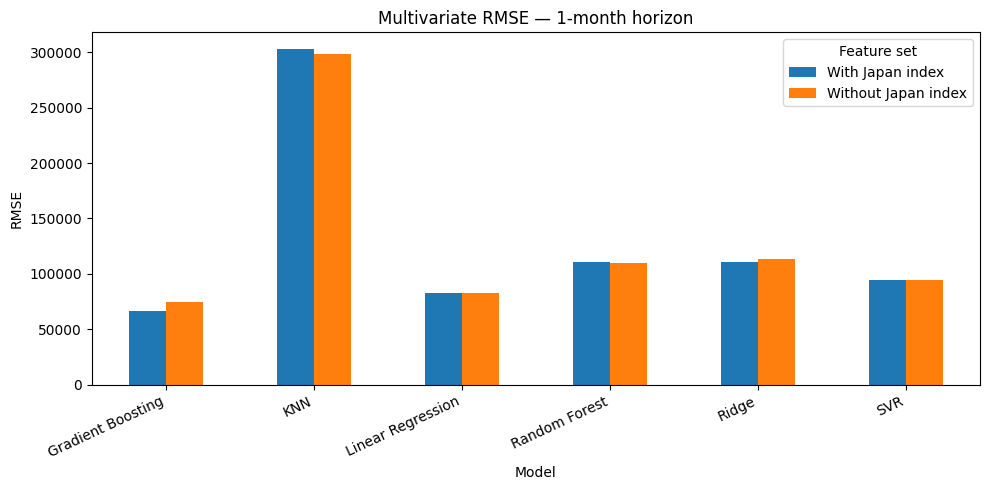

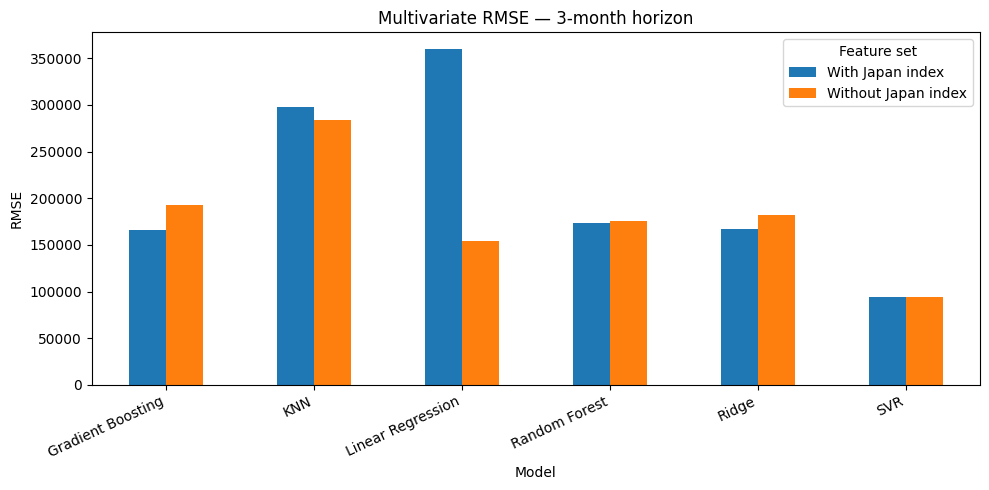

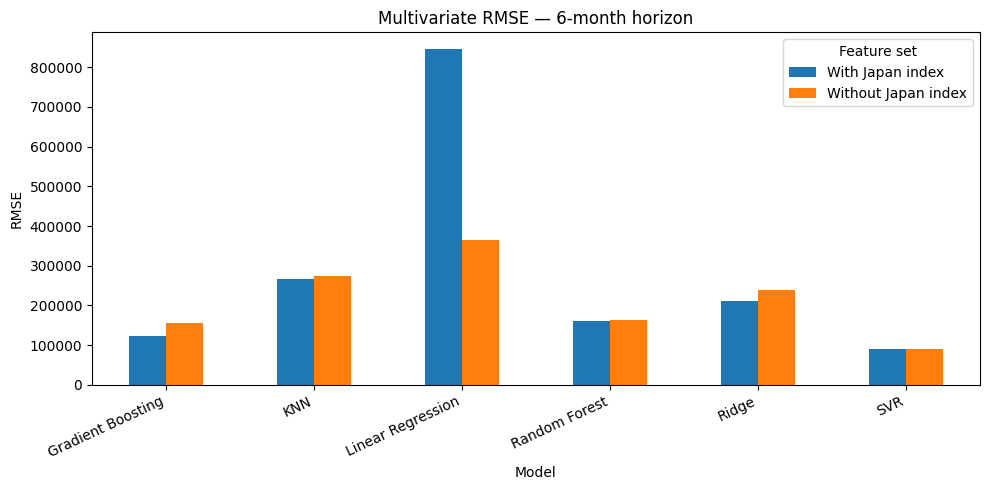

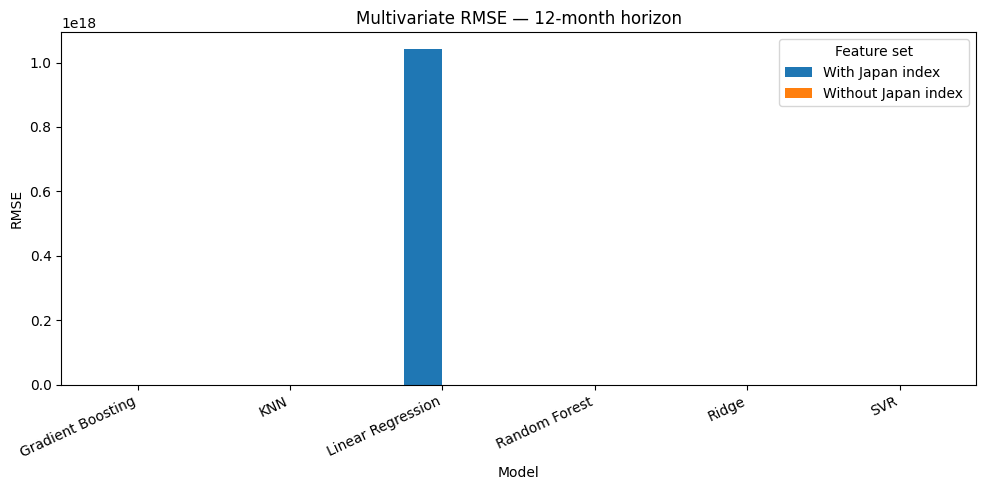

In [19]:
for h in HORIZONS:
    p=results[results.Horizon==h].pivot(index="Model",columns="Feature set",values="RMSE")
    fig,ax=plt.subplots(figsize=(10,5)); p.plot(kind="bar",ax=ax)
    ax.set(title=f"Multivariate RMSE — {h}-month horizon",ylabel="RMSE",xlabel="Model")
    plt.xticks(rotation=25,ha="right"); plt.tight_layout()
    fig.savefig(FIGURES_DIR/f"11_multivariate_rmse_h{h}.png",dpi=180); plt.show()

## Best one-month multivariate model and prediction interval

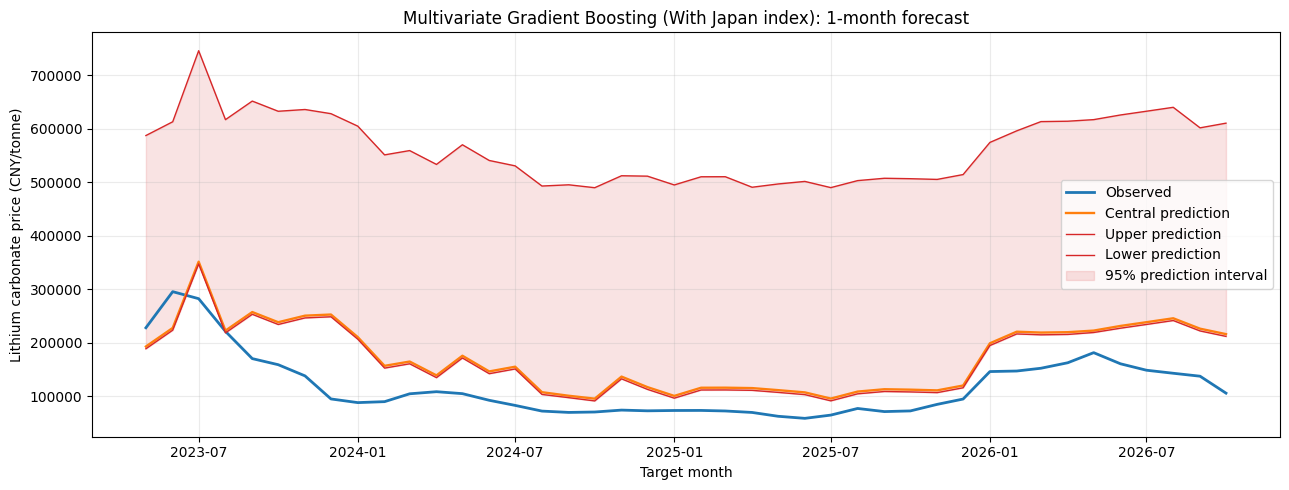

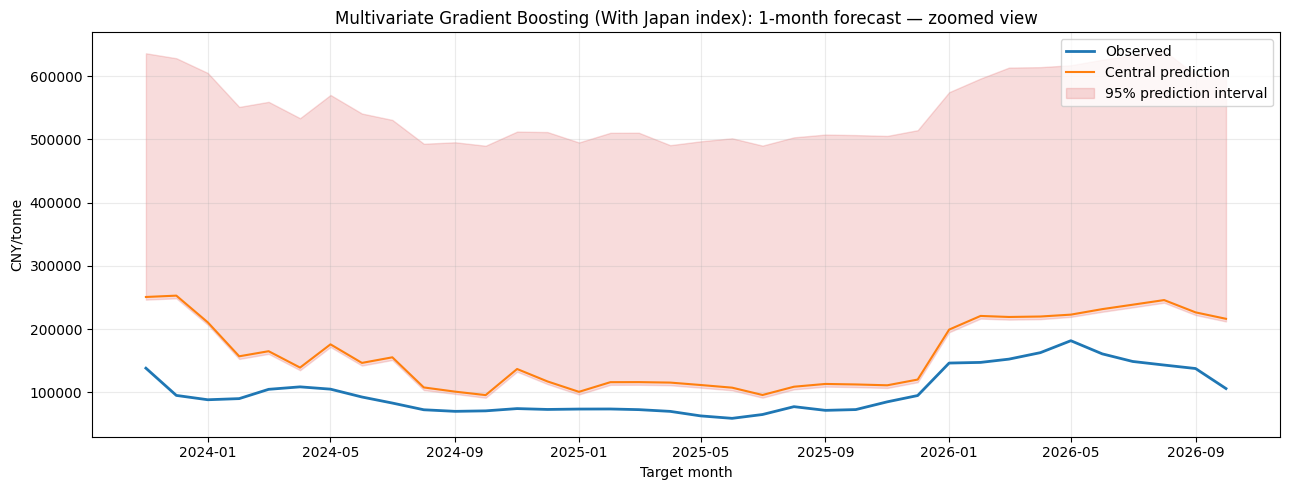

Empirical test interval coverage: 0.071


In [20]:
bestrow=results[results.Horizon==1].sort_values("RMSE").iloc[0]
key=(bestrow["Feature set"],1,bestrow["Model"])
Xtr,Xte,ytr,yte,pred=store[key]
resid=calibration_residuals(Xtr,ytr,bestrow["Model"])
lower,upper=prediction_interval(pred,resid,n_boot=1500,block=3)
plot_forecast(yte,pred,lower,upper,
    f"Multivariate {bestrow['Model']} ({bestrow['Feature set']}): 1-month forecast",
    "12_multivariate_forecast_interval.png")
print("Empirical test interval coverage:",round(np.mean((yte.values>=lower)&(yte.values<=upper)),3))
pd.DataFrame({"actual":yte,"prediction":pred,"lower_95":lower,"upper_95":upper}).to_csv(TABLES_DIR/"multivariate_1month_predictions_and_intervals.csv")

## Learning curve for best multivariate model

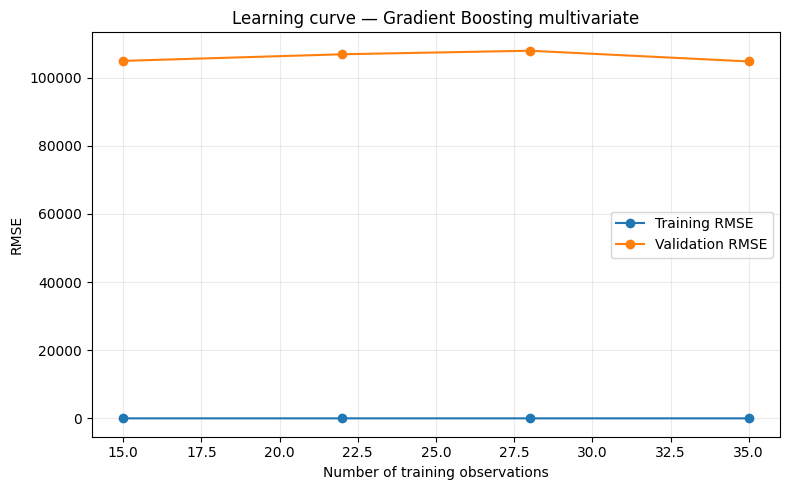

,Training observations,Training RMSE,Validation RMSE
0,15,0.011879,104942.059479
1,22,0.056424,106878.673574
2,28,0.070075,107925.260453
3,35,0.330664,104775.307631


In [21]:
learning=plot_learning_curve(model_bank()[bestrow["Model"]],Xtr,ytr,
    f"Learning curve — {bestrow['Model']} multivariate","13_multivariate_learning_curve.png")
display(learning); learning.to_csv(TABLES_DIR/"multivariate_learning_curve.csv",index=False)

## Japan index effect

In [22]:
best=results.loc[results.groupby(["Feature set","Horizon"])["RMSE"].idxmin()]
wide=best.pivot(index="Horizon",columns="Feature set",values="RMSE")
wide["RMSE difference (with Japan - without Japan)"]=wide["With Japan index"]-wide["Without Japan index"]
display(best); display(wide)
best.to_csv(TABLES_DIR/"multivariate_best_by_feature_set.csv")

,Feature set,Horizon,Model,MAE,RMSE,R2
29,With Japan index,1,Gradient Boosting,59295.190201,66729.993107,-0.342484
33,With Japan index,3,SVR,75050.750625,94601.368291,-1.698124
39,With Japan index,6,SVR,71923.156954,90949.538312,-1.669220
45,With Japan index,12,SVR,62642.806483,79213.942819,-1.669322
5,Without Japan index,1,Gradient Boosting,67775.154280,74948.082200,-0.693511
9,Without Japan index,3,SVR,75051.142286,94601.594769,-1.698137
15,Without Japan index,6,SVR,71924.018640,90950.173066,-1.669257
21,Without Japan index,12,SVR,62625.025175,79199.881505,-1.668374


Feature set,With Japan index,Without Japan index,RMSE difference (with Japan - without Japan)
Horizon,,,
1,66729.993107,74948.082200,-8218.089093
3,94601.368291,94601.594769,-0.226478
6,90949.538312,90950.173066,-0.634754
12,79213.942819,79199.881505,14.061313


## Residual and scatter diagnostics

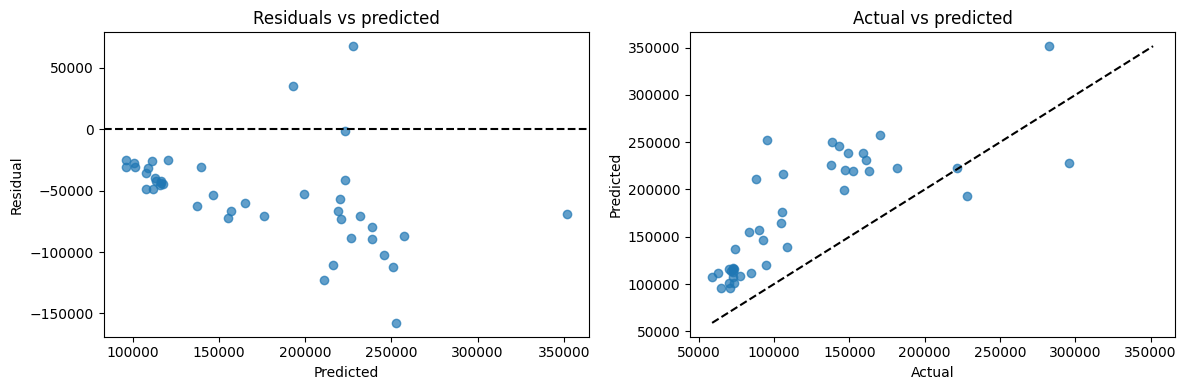

In [23]:
resid=yte.values-pred
fig,axs=plt.subplots(1,2,figsize=(12,4))
axs[0].scatter(pred,resid,alpha=.7); axs[0].axhline(0,color="black",linestyle="--")
axs[0].set(title="Residuals vs predicted",xlabel="Predicted",ylabel="Residual")
axs[1].scatter(yte.values,pred,alpha=.7)
lo=min(yte.min(),pred.min()); hi=max(yte.max(),pred.max()); axs[1].plot([lo,hi],[lo,hi],"k--")
axs[1].set(title="Actual vs predicted",xlabel="Actual",ylabel="Predicted")
plt.tight_layout(); fig.savefig(FIGURES_DIR/"14_multivariate_diagnostics.png",dpi=180); plt.show()